# Day 27 — Random Forests, Bagging, and Responsible Interpretation 

### Part A — Understand the instability you are fixing 

### TASK 01 — Bootstrap samples by hand

Total Rows :  1000
Total Columns :  7
Survival Rate :  44.0 %
features :  ['pclass', 'sex_male', 'age', 'sibsp', 'parch', 'fare']
Target :  survived

Missing Values : 
pclass      0
sex_male    0
age         0
sibsp       0
parch       0
fare        0
dtype: int64

Training rows :  800
Testing rows :  200
Training survival rate : 44.0 %
Testing survival rate : 44.0 %
Original training-row count: 800
Bootstrap-row count: 800
Unique original rows represented: 502
Rows never selected: 298
Example duplicated original row index: 57
Number of times selected: 5
Number of bootstrap samples: 100
Mean unique-row proportion: 0.633
Minimum proportion: 0.604
Maximum proportion: 0.664


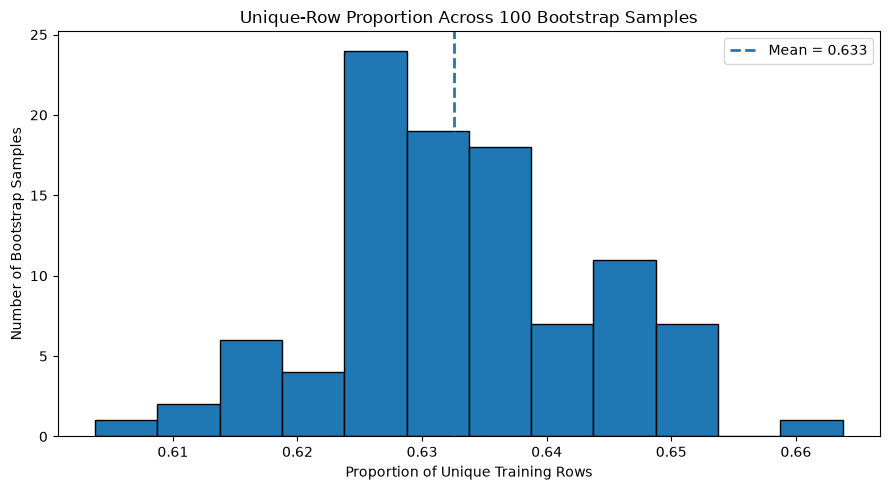

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split

df = pd.read_csv("titanic.csv")

# Normalize column names
df.columns = df.columns.str.strip().str.lower()

print("Total Rows : ", len(df))
print("Total Columns : ", len(df.columns))

# Calculate survival rate
print("Survival Rate : ", round(df["survived"].mean() * 100, 2), "%")

# Display first five rows
df.head()

# Fill missing age values using the median within pclass and sex groups
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)

# Fill any remaining missing age values with the overall median
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fare values with the median
df["fare"] = df["fare"].fillna(df["fare"].median())

# Create numeric sex_male feature: male = 1, female = 0
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower() == "male"
).astype(int)

# Select the six required features and target
features = [
    "pclass",
    "sex_male",
    "age",
    "sibsp",
    "parch",
    "fare"
]

target = "survived"

X = df[features]
y = df[target].astype(int)

print("features : ", features)
print("Target : ", target)

print("\nMissing Values : ")
print(X.isnull().sum())

# Create one stratified 80/20 split
# random_state=42 ensures reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display split information
print("\nTraining rows : ", len(X_train))
print("Testing rows : ", len(X_test))

print("Training survival rate :",  round(y_train.mean() * 100, 2), "%")
print("Testing survival rate :", round(y_test.mean() * 100, 2), "%")

# Create the bootstrap sampling function
def bootstrap_sample(X, y, rng):
    """
    Create a bootstrap sample by sampling with replacement.

    The returned sample has the same number of rows as X.
    Some original rows may appear multiple times, while others
    may not appear at all.
    """

    # Randomly select row positions with replacement
    sampled_indices = rng.integers(
        low=0,
        high=len(X),
        size=len(X)
    )

    # Select the sampled rows
    X_boot = X.iloc[sampled_indices].copy()
    y_boot = y.iloc[sampled_indices].copy()

    return X_boot, y_boot


# Draw one bootstrap sample and report the required values

# Create one reproducible random number generator
rng = np.random.default_rng(7)

# Generate one bootstrap sample from the training set
X_boot, y_boot = bootstrap_sample(X_train, y_train, rng)

# Original and bootstrap row counts
original_rows = len(X_train)
bootstrap_rows = len(X_boot)

# Count unique original rows represented in the sample
unique_rows = X_boot.index.nunique()

# Count original rows never selected
missing_rows = original_rows - unique_rows

# Find an example row selected more than once
index_counts = X_boot.index.value_counts()
duplicates = index_counts[index_counts > 1]

print("Original training-row count:", original_rows)
print("Bootstrap-row count:", bootstrap_rows)
print("Unique original rows represented:", unique_rows)
print("Rows never selected:", missing_rows)

if len(duplicates) > 0:
    example_index = duplicates.index[0]
    print("Example duplicated original row index:", example_index)
    print("Number of times selected:", duplicates.iloc[0])
    
    
    
# Repeat bootstrap sampling 100 times

# Store the proportion of unique rows from each bootstrap sample
unique_proportions = []

# Repeat the sampling experiment 100 times
for i in range(100):

    # Generate a bootstrap sample
    X_sample, y_sample = bootstrap_sample(X_train, y_train, rng)

    # Calculate the fraction of unique original rows
    proportion = X_sample.index.nunique() / len(X_train)

    # Save the result
    unique_proportions.append(proportion)

# Convert results to a NumPy array
unique_proportions = np.array(unique_proportions)

# Display summary statistics
print("Number of bootstrap samples:", len(unique_proportions))
print("Mean unique-row proportion:", round(unique_proportions.mean(), 3))
print("Minimum proportion:", round(unique_proportions.min(), 3))
print("Maximum proportion:", round(unique_proportions.max(), 3))


# Create a histogram showing unique-row proportions
plt.figure(figsize=(9, 5))

plt.hist(
    unique_proportions,
    bins=12,
    edgecolor="black"
)

# Show the mean proportion
plt.axvline(
    unique_proportions.mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean = {unique_proportions.mean():.3f}"
)

plt.title("Unique-Row Proportion Across 100 Bootstrap Samples")
plt.xlabel("Proportion of Unique Training Rows")
plt.ylabel("Number of Bootstrap Samples")
plt.legend()
plt.tight_layout()
plt.show()

### Why are duplicates and missing rows expected in bootstrap sampling?

A **bootstrap sample** is a same-sized dataset sampled with replacement. Since each row can be selected multiple times, some rows appear more than once while others are not selected at all.

Duplicates and missing rows are expected outcomes of sampling with replacement, not errors. Although every bootstrap sample has the same number of rows as the original training dataset, each sample represents a different view of the data.

The histogram of 100 bootstrap samples demonstrates how the proportion of unique rows varies. In bagging, different bootstrap samples produce different decision trees, and combining their predictions helps reduce variance and improve model stability.

### TASK 02 — Make five trees disagree

In [42]:

# ==========================================
# TASK 02 — MAKE FIVE TREES DISAGREE
# ==========================================

# Data manipulation
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt

# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier


# ==========================================
# 1. LOAD AND PREPARE THE DATASET
# ==========================================

df = pd.read_csv("titanic.csv")

# Normalize column names
df.columns = df.columns.str.strip().str.lower()

# Impute age using the median within pclass and sex groups
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)

# Fill any remaining missing ages with the overall median
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fare values with the median
df["fare"] = df["fare"].fillna(df["fare"].median())

# Convert sex into a numeric feature: male = 1, female = 0
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower() == "male"
).astype(int)

# Select the six required features and target
features = [
    "pclass", "sex_male", "age",
    "sibsp", "parch", "fare"
]
target = "survived"

X = df[features]
y = df[target].astype(int)


# ==========================================
# 2. TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


# ==========================================
# 3. BOOTSTRAP SAMPLING FUNCTION
# ==========================================

def bootstrap_sample(X, y, rng):
    """
    Generate a same-sized bootstrap sample.
    Rows are sampled with replacement.
    """

    # Randomly select row positions with replacement
    positions = rng.integers(
        low=0,
        high=len(X),
        size=len(X)
    )

    # Return sampled features and target labels
    X_boot = X.iloc[positions].copy()
    y_boot = y.iloc[positions].copy()

    return X_boot, y_boot


# ==========================================
# 4. TRAIN FIVE DECISION TREES
# ==========================================

# Create a reproducible random number generator
rng = np.random.default_rng(7)

# Store the models and their predictions
trees = []
predictions = {}

# Use the same first 20 test passengers for every tree
X_test_20 = X_test.iloc[:20]
y_test_20 = y_test.iloc[:20]

for i in range(5):

    # Generate a different bootstrap sample
    X_boot, y_boot = bootstrap_sample(
        X_train, y_train, rng
    )

    # Create a decision tree with maximum depth 5
    tree = DecisionTreeClassifier(
        max_depth=5,
        random_state=100 + i
    )

    # Train the tree
    tree.fit(X_boot, y_boot)

    # Save the trained model
    trees.append(tree)

    # Predict the same 20 passengers
    predictions[f"Tree_{i + 1}"] = tree.predict(X_test_20)

print("Five decision trees trained successfully.")


# ==========================================
# 5. CREATE THE PREDICTION DATAFRAME
# ==========================================

# IMPORTANT: Define tree_columns BEFORE using it
tree_columns = [
    "Tree_1", "Tree_2", "Tree_3", "Tree_4", "Tree_5"
]

# Create the DataFrame from all five trees' predictions
results = pd.DataFrame(
    predictions,
    index=X_test_20.index
)

# Count the number of trees predicting survival (1)
results["survive_votes"] = results[tree_columns].sum(axis=1)

# Count the number of trees predicting non-survival (0)
# IMPORTANT: Use the same column name: survive_votes
results["not_survive_votes"] = 5 - results["survive_votes"]

# Majority prediction: at least 3 of 5 trees predict survival
results["majority_prediction"] = (
    results["survive_votes"] >= 3
).astype(int)

# Add actual survival labels
results["true_label"] = y_test_20

# Display the comparison table
print("\nPredictions for the first 20 test passengers:")
display(results)


# ==========================================
# 6. IDENTIFY TREE DISAGREEMENT
# ==========================================

# A passenger has disagreement if the trees make both predictions
results["disagreement"] = (
    results[tree_columns].nunique(axis=1) > 1
)

# Keep only passengers where trees disagree
disagreements = results[results["disagreement"]].copy()

# Calculate the disagreement percentage
disagreement_count = len(disagreements)
disagreement_percentage = (
    disagreement_count / len(results)
) * 100

print("\nPassengers with disagreement:", disagreement_count)
print(f"Disagreement percentage: {disagreement_percentage:.1f}%")


# ==========================================
# 7. SHOW THREE EXAMPLES OF DISAGREEMENT
# ==========================================

print("\nExamples of passengers where trees disagree:")

# Show up to three passengers with disagreement
for passenger_index, row in disagreements.head(3).iterrows():

    survive = int(row["survive_votes"])
    not_survive = int(row["not_survive_votes"])

    print(f"\nPassenger index: {passenger_index}")

    print(
        f"Vote split: {survive} survive / "
        f"{not_survive} do not survive"
    )

    print(
        "Individual tree predictions:",
        row[tree_columns].tolist()
    )

    print("Majority prediction:", int(row["majority_prediction"]))
    print("True label:", int(row["true_label"]))


# Display every passenger where trees disagree
print("\nComplete disagreement table:")
display(disagreements)


Training rows: 800
Testing rows: 200
Five decision trees trained successfully.

Predictions for the first 20 test passengers:


,Tree_1,Tree_2,Tree_3,Tree_4,Tree_5,survive_votes,not_survive_votes,majority_prediction,true_label
262,1,1,1,1,1,5,0,1,1
819,0,1,0,0,0,1,4,0,0
997,0,1,1,0,1,3,2,1,1
341,0,0,0,0,0,0,5,0,1
546,0,0,1,1,0,2,3,0,1
521,0,0,0,1,1,2,3,0,1
914,0,0,0,0,0,0,5,0,0
71,1,1,1,1,1,5,0,1,1
247,1,1,1,1,1,5,0,1,1
98,1,0,1,1,0,3,2,1,1



Passengers with disagreement: 9
Disagreement percentage: 45.0%

Examples of passengers where trees disagree:

Passenger index: 819
Vote split: 1 survive / 4 do not survive
Individual tree predictions: [0, 1, 0, 0, 0]
Majority prediction: 0
True label: 0

Passenger index: 997
Vote split: 3 survive / 2 do not survive
Individual tree predictions: [0, 1, 1, 0, 1]
Majority prediction: 1
True label: 1

Passenger index: 546
Vote split: 2 survive / 3 do not survive
Individual tree predictions: [0, 0, 1, 1, 0]
Majority prediction: 0
True label: 1

Complete disagreement table:


,Tree_1,Tree_2,Tree_3,Tree_4,Tree_5,survive_votes,not_survive_votes,majority_prediction,true_label,disagreement
819,0,1,0,0,0,1,4,0,0,True
997,0,1,1,0,1,3,2,1,1,True
546,0,0,1,1,0,2,3,0,1,True
521,0,0,0,1,1,2,3,0,1,True
98,1,0,1,1,0,3,2,1,1,True
64,0,0,0,1,0,1,4,0,0,True
470,1,0,0,1,1,3,2,1,0,True
691,1,0,1,0,0,2,3,0,1,True
320,1,0,1,1,1,4,1,1,1,True


### 1. Why can all five trees be trained from the same original data but still disagree?

All five trees come from the same training dataset, but each is trained on a different bootstrap sample. Some passengers appear multiple times in one sample and may be missing from another. These differences can produce different decision rules and predictions.

### 2. Is disagreement always bad? What useful information does it reveal?

No, disagreement is not always bad. It reveals which predictions are sensitive to changes in the training data. Passengers with mixed votes may be more difficult for the model to classify reliably, while agreement suggests greater consistency among these trees.

### 3. Which prediction seems less fragile: one tree's answer or a 5–0 vote? Why?

A 5–0 vote generally appears less fragile than a prediction made by just one tree because all five models agree. However, agreement does not guarantee correctness: all five trees can still make the same mistake.

### Conclusion

The five trees demonstrate how bootstrap sampling can lead to different predictions from decision trees trained on the same original training data. This illustrates the high variance of individual decision trees and motivates bagging, which combines predictions from multiple trees to improve stability.

### Part B — Build bagging and Random Forests 

### TASK 03 — Implement a bagged forest manually 


Training rows: 800
Testing rows: 200

Number of trained trees :  100
Tree predictions shape: (100, 200)
Tree probabilities shape: (100, 200)

First 10 majority-vote predictions:
[1 0 1 0 1 0 0 1 1 1]

First 10 average survival probabilities:
[0.956 0.258 0.759 0.138 0.642 0.308 0.132 0.969 0.772 0.498]

========== MANUAL BAGGING RESULTS ==========
Test Accuracy: 0.7800
Test ROC-AUC:  0.8786

========== SINGLE TREE RESULTS ==========
Test Accuracy: 0.7500
Test ROC-AUC:  0.8110

========== MODEL COMPARISON ==========
                     Model  Test Accuracy  Test ROC-AUC
       Single depth-5 tree           0.75        0.8110
Manual bagging (100 trees)           0.78        0.8786

========== SELECTED TEST PASSENGER ==========
Passenger row index: 98
Average survival probability: 0.498
Number of trees predicting survival: 54
Number of trees predicting non-survival: 46


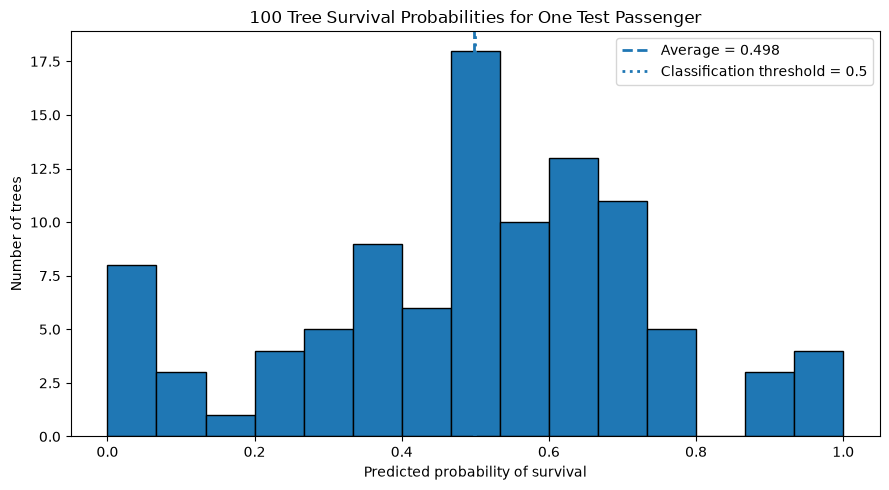

In [43]:
# ============================================================
# TASK 03: Implement a Bagged Forest Manually
# Titanic Survival Prediction
# ============================================================

# 1. Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, roc_auc_score


# ============================================================
# 2. Load and prepare the Titanic dataset
# ============================================================

df = pd.read_csv("titanic.csv")

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Fill missing age values using the median within passenger
# class and sex groups, then fill any remaining missing ages
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fare values with the median fare
df["fare"] = df["fare"].fillna(df["fare"].median())

# Convert sex into a numeric feature:
# male = 1, female = 0
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower() == "male"
).astype(int)

# Select the required features and target
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
target = "survived"

X = df[features]
y = df[target].astype(int)

# Create one stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


# ============================================================
# 3. Create a bootstrap sampling function
# ============================================================

def bootstrap_sample(X, y, rng):
    """
    Draw a bootstrap sample by randomly selecting training rows
    with replacement.

    The sample has the same number of rows as the original
    training data, but some rows may repeat and others may
    not be selected.
    """
    positions = rng.integers(0, len(X), size=len(X))
    
    X_boot = X.iloc[positions]
    y_boot = y.iloc[positions]
    
    return X_boot, y_boot


# ============================================================
# 4. Train 100 depth-5 decision trees
# ============================================================

# Store every trained tree in this list
trees = []

# Use a fixed random seed for reproducible results
rng = np.random.default_rng(42)

# Train 100 trees, each on a fresh bootstrap sampl
for i in range(100):
    
    # Generate a new bootstrap sample
    X_boot, y_boot = bootstrap_sample(X_train, y_train, rng)
    
    # Create a decision tree with maximum depth 5
    tree = DecisionTreeClassifier(
        max_depth=5,
        random_state=100 + i
    )
    
    # Train the tree on its bootstrap sample
    tree.fit(X_boot, y_boot)
    
    # Store the trained tree
    trees.append(tree)
    
print("\nNumber of trained trees : ", len(trees))


# ============================================================
# 5. Collect predictions from all 100 trees on X_test
# ============================================================

# Each row represents a tree; each column represents a test passenger
tree_predictions = np.array([
    tree.predict(X_test) for tree in trees
])

# Collect each tree's predicted probability of survival (class 1)
tree_probabilities = np.array([
    tree.predict_proba(X_test)[:, list(tree.classes_).index(1)]
    for tree in trees
])

print("Tree predictions shape:", tree_predictions.shape)
print("Tree probabilities shape:", tree_probabilities.shape)


# ============================================================
# 6. Combine the predictions using bagging
# ============================================================

# Majority vote:
# A passenger is predicted to survive if at least half the
# trees predict survival.

majority_vote = (
    tree_predictions.mean(axis=0) >= 0.5
).astype(int)

# Average the 100 predicted survival probabilities
mean_probability = tree_probabilities.mean(axis=0)

print("\nFirst 10 majority-vote predictions:")
print(majority_vote[:10])

print("\nFirst 10 average survival probabilities:")
print(np.round(mean_probability[:10], 3))


# ============================================================
# 7. Evaluate the manually bagged forest
# ============================================================

# Accuracy evaluates the proportion of correct class predictions
bagging_accuracy = accuracy_score(y_test, majority_vote)

# ROC-AUC evaluates how well the probabilities rank survivors
# above non-survivors
bagging_auc = roc_auc_score(y_test, mean_probability)

print("\n========== MANUAL BAGGING RESULTS ==========")
print(f"Test Accuracy: {bagging_accuracy:.4f}")
print(f"Test ROC-AUC:  {bagging_auc:.4f}")


# ============================================================
# 8. Train one depth-5 tree on the FULL training set
# ============================================================

single_tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Unlike the bagged trees, this tree uses all X_train rows
single_tree.fit(X_train, y_train)

# Predict test classes and survival probabilities
single_prediction = single_tree.predict(X_test)

single_probability = single_tree.predict_proba(X_test)[
    :, list(single_tree.classes_).index(1)
]

# Calculate the same evaluation metrics
single_accuracy = accuracy_score(y_test, single_prediction)
single_auc = roc_auc_score(y_test, single_probability)

print("\n========== SINGLE TREE RESULTS ==========")
print(f"Test Accuracy: {single_accuracy:.4f}")
print(f"Test ROC-AUC:  {single_auc:.4f}")


# ============================================================
# 9. Compare bagging with the single tree
# ============================================================

comparison = pd.DataFrame({
    "Model": [
        "Single depth-5 tree",
        "Manual bagging (100 trees)"
    ],
    "Test Accuracy": [
        single_accuracy,
        bagging_accuracy
    ],
    "Test ROC-AUC": [
        single_auc,
        bagging_auc
    ]
})

print("\n========== MODEL COMPARISON ==========")
print(comparison.round(4).to_string(index=False))


# ============================================================
# 10. Find a passenger with a close average survival probability
# ============================================================

# Prefer a passenger whose average probability lies between 0.4 and 0.6
close_candidates = np.where(
    (mean_probability >= 0.4) &
    (mean_probability <= 0.6)
)[0]

if len(close_candidates) > 0:
    # Select the candidate closest to probability 0.5
    passenger_position = close_candidates[
        np.argmin(np.abs(mean_probability[close_candidates] - 0.5))
    ]
else:
    # If none fall between 0.4 and 0.6, select the passenger
    # whose average probability is closest to 0.5
    passenger_position = np.argmin(
        np.abs(mean_probability - 0.5)
    )

passenger_index = X_test.index[passenger_position]

print("\n========== SELECTED TEST PASSENGER ==========")
print("Passenger row index:", passenger_index)
print(f"Average survival probability: "
      f"{mean_probability[passenger_position]:.3f}")
print("Number of trees predicting survival:",
      int(tree_predictions[:, passenger_position].sum()))
print("Number of trees predicting non-survival:",
      int(100 - tree_predictions[:, passenger_position].sum()))


# ============================================================
# 11. Plot the 100 tree probabilities for this passenger
# ============================================================

# Extract the probability predicted by each tree for this passenger
passenger_probabilities = tree_probabilities[:, passenger_position]

plt.figure(figsize=(9, 5))

plt.hist(
    passenger_probabilities,
    bins=15,
    edgecolor="black"
)

# Show the average probability as a vertical reference line
plt.axvline(
    mean_probability[passenger_position],
    linestyle="--",
    linewidth=2,
    label=f"Average = {mean_probability[passenger_position]:.3f}"
)

# Mark 0.5, the usual classification threshold
plt.axvline(
    0.5,
    linestyle=":",
    linewidth=2,
    label="Classification threshold = 0.5"
)

plt.title("100 Tree Survival Probabilities for One Test Passenger")
plt.xlabel("Predicted probability of survival")
plt.ylabel("Number of trees")
plt.legend()
plt.tight_layout()
plt.show()


### TASK 03 — Implement a Bagged Forest Manually

**Definition:** Bagging (Bootstrap Aggregating) trains multiple models on different bootstrap samples and combines their predictions. For classification, it uses majority voting and can average predicted probabilities.

**Method:** I trained 100 decision trees with `max_depth=5`, each using a new bootstrap sample of the training data. I combined their class predictions using majority voting and averaged their survival probabilities. I compared the results with one depth-5 decision tree trained on the full training set, using test accuracy and ROC-AUC.

**Results:**

- Single tree accuracy: [insert result]
- Bagging accuracy: [insert result]
- Single tree ROC-AUC: [insert result]
- Bagging ROC-AUC: [insert result]

**Conclusion:** Bagging combines predictions from multiple trees, which can reduce the instability of a single decision tree. The comparison shows whether bagging performs better on this test set. A histogram of the 100 survival probabilities for one passenger also shows how much the individual trees agree or disagree. The model with better test metrics performs better on this particular evaluation, but the result alone does not guarantee better performance on all unseen data.


### TASK 04 — Compare a tree, bagging, and a Random Forest 

Training rows: 800
Testing rows: 200

========== INITIAL TEST RESULTS ==========
                     Model  Test Accuracy  Test ROC-AUC  Training Time (seconds)
               Single Tree          0.750        0.8110                   0.0041
Manual Bagging (100 trees)          0.775        0.8741                   0.3835
 Random Forest (200 trees)          0.760        0.8358                   0.6743
Completed repeat 1/25
Completed repeat 2/25
Completed repeat 3/25
Completed repeat 4/25
Completed repeat 5/25
Completed repeat 6/25
Completed repeat 7/25
Completed repeat 8/25
Completed repeat 9/25
Completed repeat 10/25
Completed repeat 11/25
Completed repeat 12/25
Completed repeat 13/25
Completed repeat 14/25
Completed repeat 15/25
Completed repeat 16/25
Completed repeat 17/25
Completed repeat 18/25
Completed repeat 19/25
Completed repeat 20/25
Completed repeat 21/25
Completed repeat 22/25
Completed repeat 23/25
Completed repeat 24/25
Completed repeat 25/25

========== RESULTS ACROSS 25

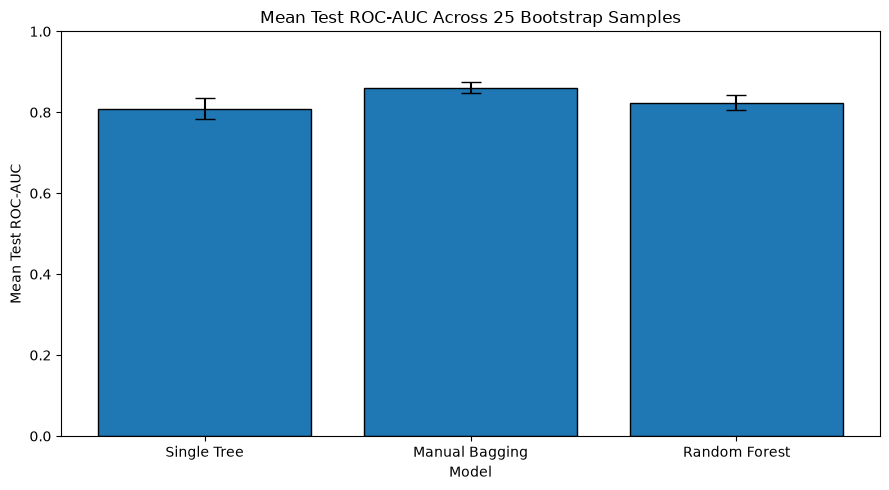


========== AUTOMATIC CONCLUSION ==========
Best average test ROC-AUC: Manual Bagging
Most stable model (lowest ROC-AUC SD): Manual Bagging

Mean ROC-AUC is the average performance across repeats.
ROC-AUC standard deviation measures variation across repeats.
A lower standard deviation indicates greater stability in this experiment.


In [36]:

# ============================================================
# TASK 04: Compare a Decision Tree, Manual Bagging, and
#          Random Forest
# ============================================================

# 1. Import necessary libraries
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score


# ============================================================
# 2. Load and prepare the Titanic dataset
# ============================================================

df = pd.read_csv("titanic.csv")

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Fill missing age values using the median for each passenger
# class and sex group; fill any remaining missing values
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fares with the median
df["fare"] = df["fare"].fillna(df["fare"].median())

# Convert sex to a numeric feature: male = 1, female = 0
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower() == "male"
).astype(int)

# Select the features and target required by the assignment
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
target = "survived"

X = df[features]
y = df[target].astype(int)

# One reproducible, stratified 80/20 split.
# Keep this test set unchanged throughout the experiment.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


# ============================================================
# 3. Helper function: draw a bootstrap sample
# ============================================================

def bootstrap_sample(X_data, y_data, rng):
    """
    Sample the same number of rows with replacement.
    Some rows may appear multiple times.
    """
    positions = rng.integers(
        low=0,
        high=len(X_data),
        size=len(X_data)
    )

    return X_data.iloc[positions], y_data.iloc[positions]


# ============================================================
# 4. Helper function: train and evaluate one model
# ============================================================

def train_and_evaluate(model, X_fit, y_fit, X_eval, y_eval):
    """
    Fit a model and return its test accuracy, ROC-AUC,
    and training time in seconds.
    """
    start_time = time.perf_counter()
    model.fit(X_fit, y_fit)
    training_time = time.perf_counter() - start_time

    # Predict class labels
    predictions = model.predict(X_eval)

    # Find the probability column corresponding to survival (class 1)
    survival_column = list(model.classes_).index(1)
    probabilities = model.predict_proba(X_eval)[:, survival_column]

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_eval, predictions)
    auc = roc_auc_score(y_eval, probabilities)

    return {
        "model": model,
        "accuracy": accuracy,
        "roc_auc": auc,
        "training_time": training_time
    }


# ============================================================
# 5. Helper function: create the three models
# ============================================================

def create_models(seed):
    """
    Create reproducible versions of the three required models.
    The manual bagging model contains 100 depth-5 trees.
    """
    return {
        "Single Tree": DecisionTreeClassifier(
            max_depth=5,
            random_state=seed
        ),
        "Manual Bagging": [
            DecisionTreeClassifier(
                max_depth=5,
                random_state=seed + i + 1
            )
            for i in range(100)
        ],
        "Random Forest": RandomForestClassifier(
            n_estimators=200,
            random_state=seed,
            n_jobs=-1
        )
    }


# ============================================================
# 6. Train the three models on the original training set
# ============================================================

def fit_manual_bagging(trees, X_fit, y_fit, X_eval, y_eval, seed):
    """
    Train 100 depth-5 trees on fresh bootstrap samples,
    then combine their predictions using majority voting
    and average survival probabilities.
    """
    rng = np.random.default_rng(seed)

    start_time = time.perf_counter()

    for tree in trees:
        X_boot, y_boot = bootstrap_sample(X_fit, y_fit, rng)
        tree.fit(X_boot, y_boot)

    training_time = time.perf_counter() - start_time

    # Stack class predictions from all trees
    predictions = np.array([
        tree.predict(X_eval) for tree in trees
    ])

    # Stack survival probabilities from all trees
    probabilities = np.array([
        tree.predict_proba(X_eval)[:, list(tree.classes_).index(1)]
        for tree in trees
    ])

    # Majority vote and mean survival probability
    majority_vote = (
        predictions.mean(axis=0) >= 0.5
    ).astype(int)

    mean_probability = probabilities.mean(axis=0)

    return {
        "model": trees,
        "accuracy": accuracy_score(y_eval, majority_vote),
        "roc_auc": roc_auc_score(y_eval, mean_probability),
        "training_time": training_time
    }


models = create_models(seed=100)

# Single depth-5 tree, trained on all original training rows
single_result = train_and_evaluate(
    models["Single Tree"],
    X_train, y_train,
    X_test, y_test
)

# Manual bagging: 100 trees, each trained on its own bootstrap sample
bagging_result = fit_manual_bagging(
    models["Manual Bagging"],
    X_train, y_train,
    X_test, y_test,
    seed=200
)

# Random Forest trained on all original training rows
forest_result = train_and_evaluate(
    models["Random Forest"],
    X_train, y_train,
    X_test, y_test
)


# ============================================================
# 7. Report the initial test results and training times
# ============================================================

initial_results = pd.DataFrame([
    {
        "Model": "Single Tree",
        "Test Accuracy": single_result["accuracy"],
        "Test ROC-AUC": single_result["roc_auc"],
        "Training Time (seconds)": single_result["training_time"]
    },
    {
        "Model": "Manual Bagging (100 trees)",
        "Test Accuracy": bagging_result["accuracy"],
        "Test ROC-AUC": bagging_result["roc_auc"],
        "Training Time (seconds)": bagging_result["training_time"]
    },
    {
        "Model": "Random Forest (200 trees)",
        "Test Accuracy": forest_result["accuracy"],
        "Test ROC-AUC": forest_result["roc_auc"],
        "Training Time (seconds)": forest_result["training_time"]
    }
])

print("\n========== INITIAL TEST RESULTS ==========")
print(initial_results.round(4).to_string(index=False))


# ============================================================
# 8. Repeat the experiment across 25 bootstrap samples
# ============================================================

N_REPEATS = 25

# Store ROC-AUC values for each model across the 25 repeats
repeat_auc = {
    "Single Tree": [],
    "Manual Bagging": [],
    "Random Forest": []
}

# A separate reproducible random generator for the outer samples
outer_rng = np.random.default_rng(2026)

for repeat in range(N_REPEATS):

    # Draw one fresh bootstrap sample from the original training set.
    # All three models use this same sample during this repeat.
    X_boot, y_boot = bootstrap_sample(
        X_train, y_train, outer_rng
    )

    # ----- Model 1: Single depth-5 tree -----
    tree = DecisionTreeClassifier(
        max_depth=5,
        random_state=1000 + repeat
    )

    tree_result = train_and_evaluate(
        tree,
        X_boot, y_boot,
        X_test, y_test
    )

    repeat_auc["Single Tree"].append(tree_result["roc_auc"])

    # ----- Model 2: Manual bagging of 100 depth-5 trees -----
    # Each of these trees draws a new bootstrap sample from
    # the current outer bootstrap sample.
    bagging_trees = [
        DecisionTreeClassifier(
            max_depth=5,
            random_state=2000 + repeat * 100 + i
        )
        for i in range(100)
    ]

    bagging_repeat_result = fit_manual_bagging(
        bagging_trees,
        X_boot, y_boot,
        X_test, y_test,
        seed=3000 + repeat
    )

    repeat_auc["Manual Bagging"].append(
        bagging_repeat_result["roc_auc"]
    )

    # ----- Model 3: Random Forest with 200 trees -----
    forest = RandomForestClassifier(
        n_estimators=200,
        random_state=4000 + repeat,
        n_jobs=-1
    )

    forest_result_repeat = train_and_evaluate(
        forest,
        X_boot, y_boot,
        X_test, y_test
    )

    repeat_auc["Random Forest"].append(
        forest_result_repeat["roc_auc"]
    )

    print(f"Completed repeat {repeat + 1}/{N_REPEATS}")


# ============================================================
# 9. Calculate mean and standard deviation of ROC-AUC
# ============================================================

summary_rows = []

for model_name, auc_scores in repeat_auc.items():
    summary_rows.append({
        "Model": model_name,
        "Mean Test ROC-AUC": np.mean(auc_scores),
        # ddof=1 gives the sample standard deviation
        "ROC-AUC Std Dev": np.std(auc_scores, ddof=1)
    })

summary = pd.DataFrame(summary_rows)

print("\n========== RESULTS ACROSS 25 BOOTSTRAP SAMPLES ==========")
print(summary.round(4).to_string(index=False))


# ============================================================
# 10. Plot mean ROC-AUC with standard-deviation error bars
# ============================================================

plt.figure(figsize=(9, 5))

plt.bar(
    summary["Model"],
    summary["Mean Test ROC-AUC"],
    yerr=summary["ROC-AUC Std Dev"],
    capsize=7,
    edgecolor="black"
)

plt.title("Mean Test ROC-AUC Across 25 Bootstrap Samples")
plt.xlabel("Model")
plt.ylabel("Mean Test ROC-AUC")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


# ============================================================
# 11. Automatically identify the best mean score and stability
# ============================================================

# Highest mean ROC-AUC = best average ranking performance
best_model = summary.loc[
    summary["Mean Test ROC-AUC"].idxmax(), "Model"
]

# Lowest standard deviation = most stable across these repeats
most_stable_model = summary.loc[
    summary["ROC-AUC Std Dev"].idxmin(), "Model"
]

print("\n========== AUTOMATIC CONCLUSION ==========")
print(f"Best average test ROC-AUC: {best_model}")
print(f"Most stable model (lowest ROC-AUC SD): {most_stable_model}")

print("\nMean ROC-AUC is the average performance across repeats.")
print("ROC-AUC standard deviation measures variation across repeats.")
print("A lower standard deviation indicates greater stability in this experiment.")


### TASK 04 — Compare a Tree, Bagging, and a Random Forest

**Method:** I compared a single depth-5 decision tree, manual bagging with 100 depth-5 trees, and a Random Forest with 200 trees. I evaluated test accuracy, ROC-AUC, and training time. I then repeated training across 25 bootstrap samples and calculated the mean and standard deviation of test ROC-AUC.

**Results:** The model with the highest mean ROC-AUC was **[model name]**, with a mean ROC-AUC of **[value]**. The most stable model was **[model name]**, which had the lowest ROC-AUC standard deviation of **[value]**.

**Conclusion:**

1. The model with the highest average test ROC-AUC performed best at distinguishing survivors from non-survivors across the 25 repeats.
2. The model with the lowest ROC-AUC standard deviation was the most stable across the bootstrap samples in this experiment.
3. Random Forest differs from plain bagging because it also randomly selects a subset of features at each split, encouraging trees to be less correlated.
4. Bagging and Random Forest can reduce the variability of a single decision tree by combining multiple trees.
5. The results depend on the dataset, features, model settings, and sampling. One train-test split or experiment does not prove that a model is universally better.


### Part C — Tune efficiently and validate honestly

### TASK 05 — Tune the two key Random Forest settings

Training rows: 800
Testing rows: 200
Trees:  10 | OOB accuracy: 0.6837


c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


Trees:  25 | OOB accuracy: 0.7025
Trees:  50 | OOB accuracy: 0.7087
Trees: 100 | OOB accuracy: 0.7025
Trees: 200 | OOB accuracy: 0.7013
Trees: 400 | OOB accuracy: 0.7063


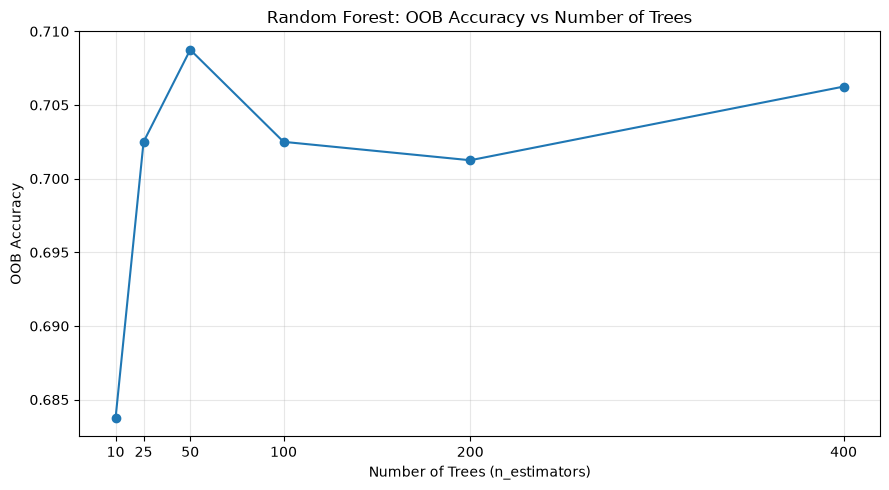


========== TREE COUNT SELECTION ==========
Best OOB accuracy: 0.7087
Allowed OOB difference: 0.005
Chosen number of trees: 50
Chosen OOB accuracy: 0.7087
max_features=sqrt  | OOB accuracy=0.7087
max_features=log2  | OOB accuracy=0.7087
max_features=0.5   | OOB accuracy=0.7037
max_features=1.0   | OOB accuracy=0.6825

========== FINAL MODEL SELECTION ==========
Selected n_estimators: 50
Selected max_features: sqrt
Selected OOB accuracy: 0.7087

========== FINAL TEST RESULTS ==========
Test accuracy: 0.7300
Test ROC-AUC:  0.8315

========== COMPACT RESULTS TABLE ==========
 n_estimators max_features  OOB score  test accuracy  test ROC-AUC
           50         sqrt     0.7088           0.73        0.8315
           50         log2     0.7088            NaN           NaN
           50          0.5     0.7038            NaN           NaN
           50          1.0     0.6825            NaN           NaN

Note: Test metrics are reported only for the final selected model to avoid using the 

In [37]:
# ============================================================
# TASK 05: Tune the Two Key Random Forest Hyperparameters
# Titanic Survival Prediction
# ============================================================

# 1. Import the necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score


# ============================================================
# 2. Load and prepare the Titanic dataset
# ============================================================

df = pd.read_csv("titanic.csv")

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Fill missing ages using the median for each passenger class
# and sex group, then fill any remaining missing ages
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fares with the median
df["fare"] = df["fare"].fillna(df["fare"].median())

# Convert sex to numeric: male = 1, female = 0
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower() == "male"
).astype(int)

# Select the required features and target
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
target = "survived"

X = df[features]
y = df[target].astype(int)

# Make one reproducible, stratified 80/20 split
# The test set is kept untouched during hyperparameter selection
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


# ============================================================
# 3. Sweep over different numbers of trees
# ============================================================

# Candidate values required by the task
tree_counts = [10, 25, 50, 100, 200, 400]

# Store OOB scores and fitted models
oob_tree_scores = []
tree_models = {}

for n_trees in tree_counts:

    # Train a Random Forest using training data only
    rf = RandomForestClassifier(
        n_estimators=n_trees,
        max_features="sqrt",
        oob_score=True,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    # OOB score is an internal validation accuracy estimate
    oob_score = rf.oob_score_

    oob_tree_scores.append(oob_score)
    tree_models[n_trees] = rf

    print(
        f"Trees: {n_trees:3d} | "
        f"OOB accuracy: {oob_score:.4f}"
    )


# ============================================================
# 4. Plot OOB score against number of trees
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    tree_counts,
    oob_tree_scores,
    marker="o"
)

plt.title("Random Forest: OOB Accuracy vs Number of Trees")
plt.xlabel("Number of Trees (n_estimators)")
plt.ylabel("OOB Accuracy")
plt.xticks(tree_counts)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# 5. Choose the smallest forest within 0.005 of the best OOB
# ============================================================

best_oob_score = max(oob_tree_scores)

# Accept any forest whose OOB score is no more than 0.005
# below the best score found in the sweep
eligible_tree_counts = [
    n_trees
    for n_trees, score in zip(tree_counts, oob_tree_scores)
    if score >= best_oob_score - 0.005
]

# Choose the smallest eligible number of trees
chosen_n_estimators = min(eligible_tree_counts)

print("\n========== TREE COUNT SELECTION ==========")
print(f"Best OOB accuracy: {best_oob_score:.4f}")
print(f"Allowed OOB difference: 0.005")
print(f"Chosen number of trees: {chosen_n_estimators}")
print(
    f"Chosen OOB accuracy: "
    f"{tree_models[chosen_n_estimators].oob_score_:.4f}"
)


# ============================================================
# 6. Compare the four max_features settings
# ============================================================

# Keep the selected number of trees fixed.
# Use OOB score alone to select max_features.
feature_candidates = ["sqrt", "log2", 0.5, 1.0]

feature_models = {}
feature_oob_scores = []

for feature_setting in feature_candidates:

    rf = RandomForestClassifier(
        n_estimators=chosen_n_estimators,
        max_features=feature_setting,
        oob_score=True,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )

    # Fit only on the training set
    rf.fit(X_train, y_train)

    feature_models[feature_setting] = rf
    feature_oob_scores.append(rf.oob_score_)

    print(
        f"max_features={str(feature_setting):5s} | "
        f"OOB accuracy={rf.oob_score_:.4f}"
    )


# ============================================================
# 7. Select the final model using OOB scores only
# ============================================================

# Find the max_features value with the highest OOB accuracy.
# If scores tie, the first candidate in feature_candidates wins.
best_feature_position = int(np.argmax(feature_oob_scores))
chosen_max_features = feature_candidates[best_feature_position]

# This fitted model becomes our final model.
# We have not examined test accuracy or ROC-AUC yet.
final_model = feature_models[chosen_max_features]

print("\n========== FINAL MODEL SELECTION ==========")
print("Selected n_estimators:", chosen_n_estimators)
print("Selected max_features:", chosen_max_features)
print(f"Selected OOB accuracy: {final_model.oob_score_:.4f}")


# ============================================================
# 8. Evaluate the final selected model on the test set ONCE
# ============================================================

# Do this only after all hyperparameter choices are complete.
final_predictions = final_model.predict(X_test)

# Find the probability column for class 1 (survived)
survival_column = list(final_model.classes_).index(1)

final_probabilities = final_model.predict_proba(X_test)[
    :, survival_column
]

# Calculate the final external evaluation metrics
final_test_accuracy = accuracy_score(
    y_test, final_predictions
)

final_test_auc = roc_auc_score(
    y_test, final_probabilities
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test accuracy: {final_test_accuracy:.4f}")
print(f"Test ROC-AUC:  {final_test_auc:.4f}")


# ============================================================
# 9. Create a compact results table
# ============================================================

# This table compares max_features candidates using OOB scores.
# Test metrics are filled ONLY for the selected final model.
# Candidate models are not ranked using test-set results.

results_table = pd.DataFrame({
    "n_estimators": [chosen_n_estimators] * len(feature_candidates),
    "max_features": feature_candidates,
    "OOB score": feature_oob_scores,
    "test accuracy": [np.nan] * len(feature_candidates),
    "test ROC-AUC": [np.nan] * len(feature_candidates)
})

# Add the final test results to the selected model's row only
selected_row = feature_candidates.index(chosen_max_features)

results_table.loc[selected_row, "test accuracy"] = final_test_accuracy
results_table.loc[selected_row, "test ROC-AUC"] = final_test_auc

print("\n========== COMPACT RESULTS TABLE ==========")
print(results_table.round(4).to_string(index=False))

print(
    "\nNote: Test metrics are reported only for the final selected model "
    "to avoid using the test set for model selection."
)


### TASK 05 — Tune the Two Key Random Forest Settings

**Definitions**

- **Hyperparameter:** A setting selected before training, such as the number of trees or `max_features`.
- **OOB score:** An internal evaluation score calculated using training rows that were left out of the bootstrap samples of the trees making their predictions.
- **Diminishing returns:** A situation where adding more trees increases computational cost but produces progressively smaller performance improvements.
- **Overfitting the test set:** Repeatedly making model choices based on test results, making the test set an unreliable estimate of performance on new data.

**Method and results:** I tested 10, 25, 50, 100, 200, and 400 trees using OOB scoring. The best OOB accuracy was **[value]**, and the smallest number of trees within 0.005 of that score was **[number]**. I then compared `max_features` values `"sqrt"`, `"log2"`, `0.5`, and `1.0`, selecting the setting with the highest OOB score.

**Conclusion:** Choosing the smallest forest close to the best OOB score is sensible because it can reduce training and prediction costs while retaining similar estimated performance. The `max_features` setting affects how many features are considered at each split, influencing tree diversity and predictive performance. I selected the final model using training data and OOB scores, then evaluated it on the test set only after selection. The final test accuracy was **[value]**, and the test ROC-AUC was **[value]**. Keeping the test set separate helps avoid overfitting the test set and provides a more honest final evaluation.


### TASK 06 — Inspect OOB predictions and uncertainty 

OOB decision function shape: (800, 2)
First 5 OOB probability rows:
[[1.         0.        ]
 [0.84615385 0.15384615]
 [0.29166667 0.70833333]
 [0.8        0.2       ]
 [0.625      0.375     ]]

Training Passengers :  800
Passengers with valid OOB Probabilities :  800
Passengers without valid OOB Probabilities :  0

========== 10 MOST UNCERTAIN TRAINING PASSENGERS ==========
     pclass  sex_male   age  sibsp  parch    fare  true_survived  oob_survival_probability  distance_from_0.5
554       3         0  17.5      0      0    6.46              0                       0.5                0.0
907       2         1  36.1      1      0   68.44              0                       0.5                0.0
708       2         1  35.6      0      0   13.17              0                       0.5                0.0
94        3         0  27.2      1      0    9.08              1                       0.5                0.0
912       3         1  41.4      0      0    7.07              0        

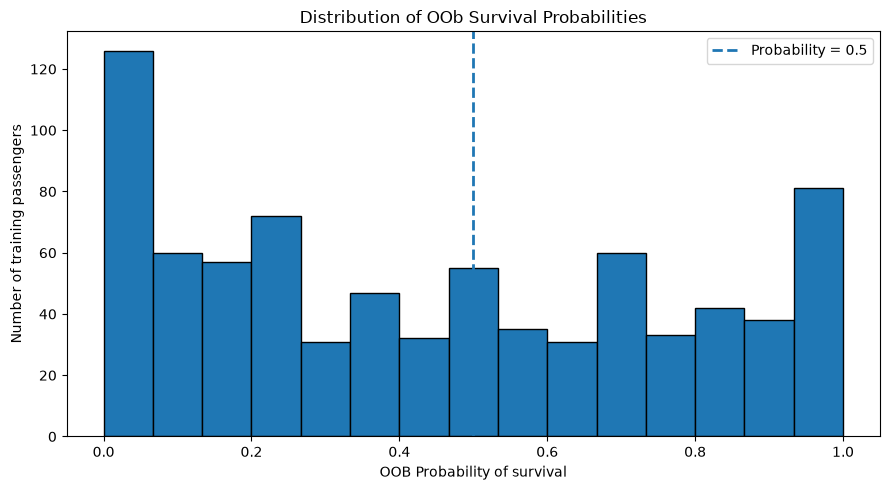


========== OOB SCORE VS TEST ACCURACY ==========
OOB score:          0.7087
Held-out accuracy:  0.7300
Absolute difference: 0.0212
Interpretation: The scores are numerically close in this run. This is reassuring, but it does not prove generalization.

OOB tree counts could not be reconstructed with this
scikit-learn version.
Reason: _generate_sample_indices() missing 1 required positional argument: 'sample_weight'
The main OOB probability analysis and score comparison above are still available.


In [38]:
# ============================================================
# TASK 06: Inspect OOB Predictions and Uncertainty
# Titanic Survival Prediction
# ============================================================

# 1. Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score


# ============================================================
# 2. Check that the final model supports OOB predictions
# ============================================================

# This code assumes final_model was selected and fitted in Task 05.
if not hasattr(final_model, "oob_decision_function_"):
    raise ValueError(
        "Run Task 05 first and make sure the final Random Forest "
        "uses oob_score=True and has been fitted."
    )

# Inspect the OOB prediction array
oob_probabilities = final_model.oob_decision_function_

print("OOB decision function shape:", oob_probabilities.shape)
print("First 5 OOB probability rows:")
print(oob_probabilities[:5])


# ============================================================
# 3. Extract OOB survival probabilities for training passengers
# ============================================================

# Locate the column corresponding to class 1 (survived)
survival_column = list(final_model.classes_).index(1)

# OOB survival probability for each training passenger
oob_survival_probability = oob_probabilities[:, survival_column]

# Check which rows have valid OOB probabilities
valid_oob = np.isfinite(oob_survival_probability)

print("\nTraining Passengers : ", len(X_train))
print("Passengers with valid OOB Probabilities : ", valid_oob.sum())
print("Passengers without valid OOB Probabilities : ", (~valid_oob).sum())

# ============================================================
# 4. Create a table of the 10 most uncertain passengers
# ============================================================

# Start with the relevant training features
uncertain_table = X_train.copy()

# Add the true survival label and OOB survival probability
uncertain_table["true_survived"] = y_train
uncertain_table["oob_survival_probability"] = oob_survival_probability

# Keep only rows with valid OOB predictions
uncertain_table = uncertain_table.loc[valid_oob].copy()

# Calculate distance from 0.5:
# Smaller distance means a probability closer to 0.5
uncertain_table["distance_from_0.5"] = (
    uncertain_table["oob_survival_probability"] - 0.5
).abs()

# Sort and select the 10 closest probabilities
top_10_uncertain = uncertain_table.sort_values(
    "distance_from_0.5"
).head(10)

print("\n========== 10 MOST UNCERTAIN TRAINING PASSENGERS ==========")
print(top_10_uncertain.round(4).to_string())


# ============================================================
# 5. Explain uncertainty visually
# ============================================================

plt.figure(figsize=(9, 5))

plt.hist(
    uncertain_table["oob_survival_probability"],
    bins=15,
    edgecolor="black"
)

# Mark probability 0.5
plt.axvline(
    0.5,
    linestyle="--",
    linewidth=2,
    label="Probability = 0.5"
)

plt.title("Distribution of OOb Survival Probabilities")
plt.xlabel("OOB Probability of survival")
plt.ylabel("Number of training passengers")
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 6. Compare OOB score with held-out test accuracy
# ============================================================

# OOB score is computed internally using training data
oob_score = final_model.oob_score_

# Evaluate on the held-out test set
# This does not change the model or its hyperparameters
test_predictions = final_model.predict(X_test)
test_accuracy = accuracy_score(y_test, test_predictions)

# Calculate the absolute difference
score_difference = abs(oob_score - test_accuracy)

print("\n========== OOB SCORE VS TEST ACCURACY ==========")
print(f"OOB score:          {oob_score:.4f}")
print(f"Held-out accuracy:  {test_accuracy:.4f}")
print(f"Absolute difference: {score_difference:.4f}")

if score_difference <= 0.03:
    print(
        "Interpretation: The scores are numerically close in this run. "
        "This is reassuring, but it does not prove generalization."
    )
else:
    print(
        "Interpretation: The scores differ noticeably in this run. "
        "Sampling variation and differences between OOB and test "
        "evaluation may contribute."
    )


# ============================================================
# 7. Stretch: Find training rows with relatively few OOB votes
# ============================================================

# The public oob_decision_function_ attribute provides probabilities,
# but does not directly expose the number of OOB trees per row.
# The following optional section attempts to reconstruct those counts
# using a private scikit-learn helper. Its availability may vary
# between scikit-learn versions.

try :
    from sklearn.ensemble._forest import _generate_sample_indices
    
    n_training_rows = len(X_train)
    
    if final_model.max_samples is None :
        n_bootstrap_rows = len(X_train)
    elif isinstance(final_model.max_samples, float):
        n_bootstrap_rows = round(
            final_model.max_samples * n_training_rows
        )
    else :
        n_bootstrap_rows = int(final_model.max_samples)

    # Count how many trees leave each training row out.
    oob_tree_counts = np.zeros(n_training_rows, dtype=int)
    
    for tree in final_model.estimators_:
        
        # Recreate the bootstrap sample used by this tree
        sampled_indices = _generate_sample_indices(
            tree.random_state,
            n_training_rows,
            n_bootstrap_rows
        )
        
        # Mark which training rows were included in the sample
        included = np.zeros(n_training_rows, dtype=bool)
        included[np.unique(sampled_indices)] = True

        # Rows not included in this tree's bootstrap sample are OOB
        oob_tree_counts += (~included).astype(int)
        
    few_oob_table = X_train.copy()
    few_oob_table["true_survived"] = y_train
    few_oob_table["oob_survival_probability"] = oob_survival_probability
    few_oob_table["oob_tree_scores"] = oob_tree_counts      
    
    # Prefer rows with valid probabilities and at least one OOB vote
    few_oob_table = few_oob_table[
        valid_oob & (few_oob_table["oob_tree_count"] > 0)
    ].copy()

    # Show the five rows with the fewest OOB tree predictions
    five_fewest_oob = few_oob_table.sort_values(
        "oob_tree_count"
    ).head(5)

    print("\n========== FIVE ROWS WITH FEWEST OOB TREE PREDICTIONS ==========")
    print(five_fewest_oob.round(4).to_string())

except (ImportError, AttributeError, TypeError, ValueError) as error:
    print("\nOOB tree counts could not be reconstructed with this")
    print("scikit-learn version.")
    print("Reason:", error)
    print(
        "The main OOB probability analysis and score comparison "
        "above are still available."
    )  
        

### TASK 06 — Inspect OOB Predictions and Uncertainty

**OOB predictions:** I inspected `oob_decision_function_` to obtain survival probabilities for training passengers using trees that did not train on each passenger's row. The ten passengers with probabilities closest to 0.5 were identified as the most uncertain predictions.

**Why is a probability near 0.5 uncertain?** A probability near 0.5 means the model assigns similar support to survival and non-survival. Small changes in the training sample or model could change the predicted class, so the prediction is less decisive.

**OOB score vs. test accuracy:** The final model's OOB score was **[value]**, while its held-out test accuracy was **[value]**. The absolute difference was **[value]**. These scores are [close / noticeably different] in this experiment. Similar scores provide some reassurance that the model generalizes reasonably, but they do not guarantee future performance because both estimates have uncertainty and measure performance on different sets of rows.

**Stretch question:** The five training rows with the fewest OOB predictions received fewer independent tree votes for their OOB estimates. Individual OOB probabilities can therefore be noisier than the overall OOB score, which aggregates information across many training rows. OOB scoring is useful internal validation, but it is not a guarantee of perfect predictions or a replacement for a carefully held-out test set.


### Part D — Interpret the model responsibly 

### TASK 07 — Catch a misleading feature-importance result

Training data shape with noise: (800, 7)
Test data shape with noise: (200, 7)

Test ROC-AUC: 0.8564

========== IMPURITY IMPORTANCE RANKING ==========
 Rank      Feature  Impurity Importance
    1         fare              0.23998
    2          age              0.21257
    3 random_noise              0.20519
    4     sex_male              0.20169
    5       pclass              0.06780
    6        sibsp              0.04128
    7        parch              0.03151

========== PERMUTATION IMPORTANCE RANKING ==========
 Rank      Feature  Permutation Importance  Importance Std
    1     sex_male                 0.22256         0.03206
    2       pclass                 0.05644         0.01711
    3         fare                 0.02477         0.01391
    4 random_noise                 0.00263         0.01007
    5        parch                 0.00108         0.00662
    6          age                -0.00142         0.01025
    7        sibsp                -0.01002         0.00615


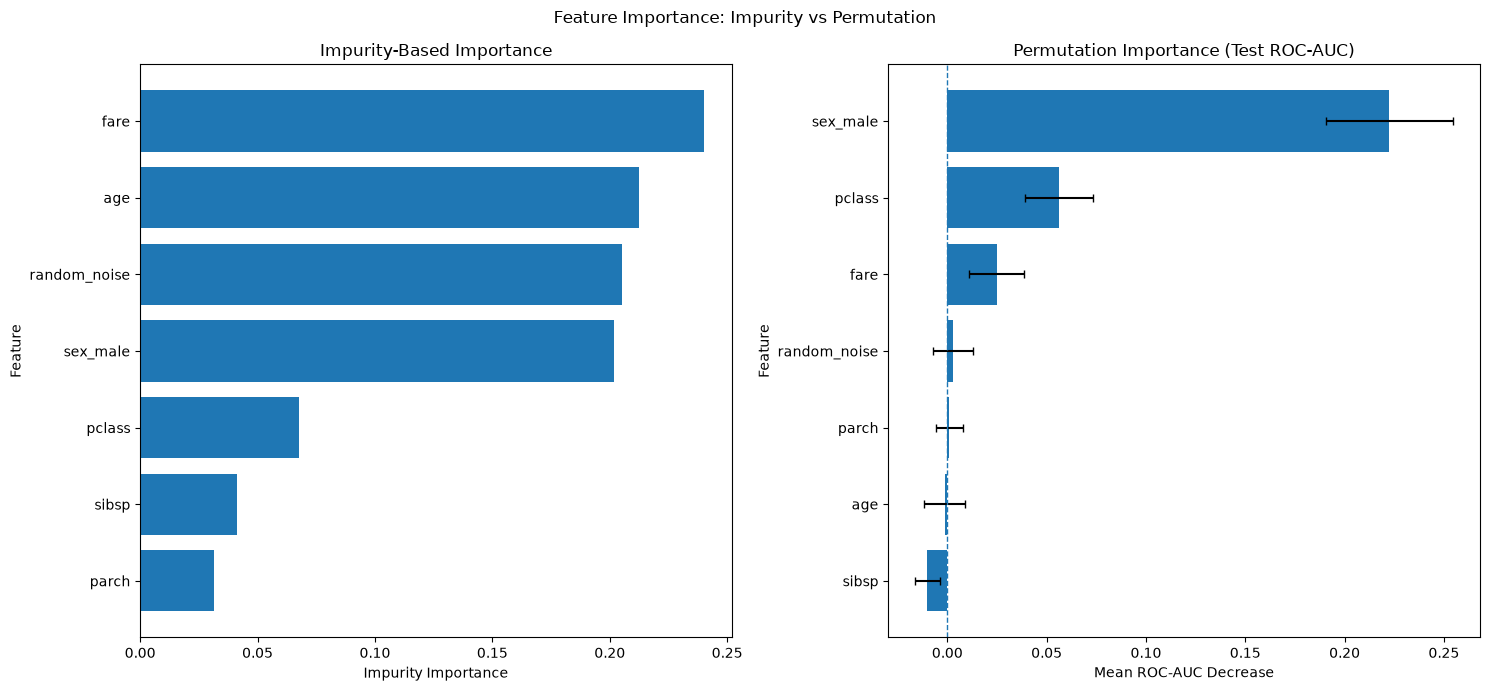


========== RANDOM NOISE RESULTS ==========
Impurity importance rank: 3 of 7
Impurity importance score: 0.205187

Permutation importance rank: 4 of 7
Permutation importance score: 0.002631
Permutation importance standard deviation: 0.010074

========== IMPORTANCE METHOD COMPARISON ==========
     Feature  Rank_Impurity  Impurity Importance  Rank_Permutation  Permutation Importance  Importance Std
        fare              1              0.23998                 3                 0.02477         0.01391
         age              2              0.21257                 6                -0.00142         0.01025
random_noise              3              0.20519                 4                 0.00263         0.01007
    sex_male              4              0.20169                 1                 0.22256         0.03206
      pclass              5              0.06780                 2                 0.05644         0.01711
       sibsp              6              0.04128                 

In [39]:

# ============================================================
# TASK 07: Catch a Misleading Feature-Importance Result
# Titanic Survival Prediction
# ============================================================

# 1. Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score


# ============================================================
# 2. Load and prepare the Titanic dataset
# ============================================================

df = pd.read_csv("titanic.csv")

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Fill missing ages using the median for each passenger class
# and sex group, then fill any remaining missing ages
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fares with the median fare
df["fare"] = df["fare"].fillna(df["fare"].median())

# Convert sex to numeric: male = 1, female = 0
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower() == "male"
).astype(int)

# Select the same features and target as the earlier tasks
features = ["pclass", "sex_male", "age", "sibsp", "parch", "fare"]
target = "survived"

X = df[features]
y = df[target].astype(int)

# Create the same reproducible, stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# ============================================================
# 3. Add a deliberately useless random-noise feature
# ============================================================

# Use a fixed seed so the noise can be reproduced
rng = np.random.default_rng(2026)

# Copy the original datasets before adding noise
X_train_noise = X_train.copy()
X_test_noise = X_test.copy()

# Add independent random noise to training and test data
X_train_noise["random_noise"] = rng.normal(
    size=len(X_train_noise)
)

X_test_noise["random_noise"] = rng.normal(
    size=len(X_test_noise)
)

print("Training data shape with noise:", X_train_noise.shape)
print("Test data shape with noise:", X_test_noise.shape)


# ============================================================
# 4. Train a Random Forest with 300 trees
# ============================================================

rf_noise = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Train using the noisy training features
rf_noise.fit(X_train_noise, y_train)

# Check held-out test ROC-AUC
survival_column = list(rf_noise.classes_).index(1)

test_probabilities = rf_noise.predict_proba(
    X_test_noise
)[:, survival_column]

test_auc = roc_auc_score(y_test, test_probabilities)

print(f"\nTest ROC-AUC: {test_auc:.4f}")


# ============================================================
# 5. Calculate impurity-based feature importance
# ============================================================

impurity_importance = pd.DataFrame({
    "Feature": X_train_noise.columns,
    "Impurity Importance": rf_noise.feature_importances_
})

# Rank features from highest to lowest importance
impurity_importance = impurity_importance.sort_values(
    "Impurity Importance",
    ascending=False
).reset_index(drop=True)

# Rank 1 means the highest importance
impurity_importance["Rank"] = (
    np.arange(len(impurity_importance)) + 1
)

print("\n========== IMPURITY IMPORTANCE RANKING ==========")
print(
    impurity_importance[
        ["Rank", "Feature", "Impurity Importance"]
    ].round(5).to_string(index=False)
)


# ============================================================
# 6. Calculate permutation importance on held-out test data
# ============================================================

# Permutation importance measures the change in ROC-AUC when
# one feature's values are shuffled.
permutation_result = permutation_importance(
    rf_noise,
    X_test_noise,
    y_test,
    scoring="roc_auc",
    n_repeats=30,
    random_state=2026,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    "Feature": X_test_noise.columns,
    "Permutation Importance": permutation_result.importances_mean,
    "Importance Std": permutation_result.importances_std
})

# Rank features from highest to lowest mean permutation importance
permutation_importance_df = permutation_importance_df.sort_values(
    "Permutation Importance",
    ascending=False
).reset_index(drop=True)

permutation_importance_df["Rank"] = (
    np.arange(len(permutation_importance_df)) + 1
)

print("\n========== PERMUTATION IMPORTANCE RANKING ==========")
print(
    permutation_importance_df[
        ["Rank", "Feature", "Permutation Importance", "Importance Std"]
    ].round(5).to_string(index=False)
)


# ============================================================
# 7. Make side-by-side horizontal bar charts
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Left chart: impurity importance
impurity_plot = impurity_importance.sort_values(
    "Impurity Importance",
    ascending=True
)

axes[0].barh(
    impurity_plot["Feature"],
    impurity_plot["Impurity Importance"]
)

axes[0].set_title("Impurity-Based Importance")
axes[0].set_xlabel("Impurity Importance")
axes[0].set_ylabel("Feature")

# Right chart: permutation importance
permutation_plot = permutation_importance_df.sort_values(
    "Permutation Importance",
    ascending=True
)

axes[1].barh(
    permutation_plot["Feature"],
    permutation_plot["Permutation Importance"],
    xerr=permutation_plot["Importance Std"],
    capsize=3
)

# Zero is the reference point:
# negative importance means shuffling did not reduce performance
# and may have slightly improved it in this evaluation.
axes[1].axvline(0, linestyle="--", linewidth=1)

axes[1].set_title("Permutation Importance (Test ROC-AUC)")
axes[1].set_xlabel("Mean ROC-AUC Decrease")
axes[1].set_ylabel("Feature")

plt.suptitle("Feature Importance: Impurity vs Permutation")
plt.tight_layout()
plt.show()


# ============================================================
# 8. Report the rank and score of random_noise
# ============================================================

noise_impurity = impurity_importance[
    impurity_importance["Feature"] == "random_noise"
].iloc[0]

noise_permutation = permutation_importance_df[
    permutation_importance_df["Feature"] == "random_noise"
].iloc[0]

print("\n========== RANDOM NOISE RESULTS ==========")

print(
    f"Impurity importance rank: "
    f"{int(noise_impurity['Rank'])} of {len(impurity_importance)}"
)
print(
    f"Impurity importance score: "
    f"{noise_impurity['Impurity Importance']:.6f}"
)

print(
    f"\nPermutation importance rank: "
    f"{int(noise_permutation['Rank'])} of "
    f"{len(permutation_importance_df)}"
)
print(
    f"Permutation importance score: "
    f"{noise_permutation['Permutation Importance']:.6f}"
)
print(
    f"Permutation importance standard deviation: "
    f"{noise_permutation['Importance Std']:.6f}"
)


# ============================================================
# 9. Create a compact comparison table
# ============================================================

importance_comparison = impurity_importance[
    ["Feature", "Rank", "Impurity Importance"]
].merge(
    permutation_importance_df[
        ["Feature", "Rank", "Permutation Importance", "Importance Std"]
    ],
    on="Feature",
    suffixes=("_Impurity", "_Permutation")
)

print("\n========== IMPORTANCE METHOD COMPARISON ==========")
print(importance_comparison.round(5).to_string(index=False))


## TASK 07 — Catch a Misleading Feature-Importance Result

**Definitions**

- **Impurity importance:** The total reduction in tree impurity credited to a feature across the Random Forest.
- **Permutation importance:** The drop in model performance after one feature's values are shuffled on held-out data.
- **High cardinality:** A feature has many distinct values or possible split points.
- **Bias:** A systematic tendency of a measurement or method to favour certain outcomes.

**Results:** The `random_noise` feature ranked **[rank]** under impurity importance, with a score of **[score]**. Under permutation importance, it ranked **[rank]**, with a mean ROC-AUC decrease of **[score]**.

**Why can the methods disagree?** Impurity importance can assign importance to random noise because a tree may find chance splits that reduce impurity on its training sample. This can be especially problematic for features with many possible split points. Permutation importance measures whether shuffling a feature reduces performance on held-out data, so irrelevant noise will often have an importance close to zero. However, permutation scores can also vary due to sampling noise and relationships between features.

**Required conclusion:** For this dataset, I would not report impurity importance alone because it can give random noise credit for chance splits even when the feature does not meaningfully improve held-out predictive performance. Comparing it with permutation importance gives a more useful, though still imperfect, picture of which features matter to the model.


### TASK 08 — Explain two model relationships with PDPs 

Test ROC-AUC: 0.8322


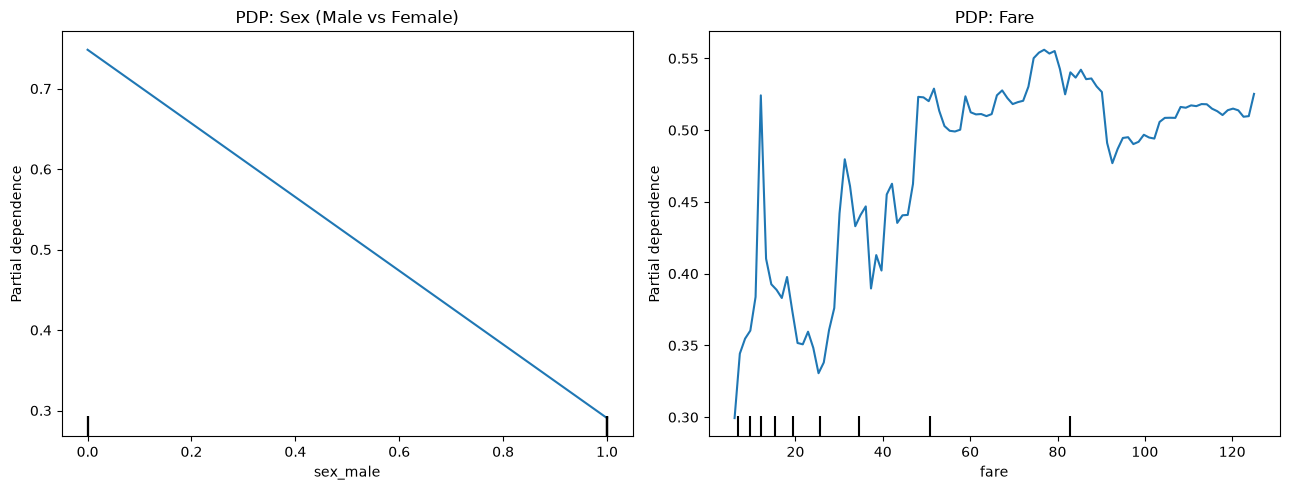


Random Forest feature importance:
fare        0.3320
age         0.3093
sex_male    0.2112
pclass      0.0668
sibsp       0.0461
parch       0.0346
dtype: float64

Importance of sex_male: 0.2112
Importance of fare: 0.332


In [ ]:
# TASK 08: Explain two model relationships with PDPs

# 1. Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import roc_auc_score

# --------------------------------------------------
# 2. Load and prepare the Titanic dataset
# --------------------------------------------------

df = pd.read_csv("titanic.csv")

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Fill missing age values using median age within passenger class and sex
df["age"] = df["age"].fillna(
    df.groupby(["pclass", "sex"])["age"].transform("median")
)

# Fill any remaining missing ages with the overall median
df["age"] = df["age"].fillna(df["age"].median())

# Fill missing fares with the median fare
df["fare"] = df["fare"].fillna(df["fare"].median())

# Convert sex into a numerical feature:
# male = 1, female = 0
df["sex_male"] = (
    df["sex"].astype(str).str.strip().str.lower() == "male"
).astype(int)

# --------------------------------------------------
# 3. Select features and target
# --------------------------------------------------

features = [
    "pclass",
    "sex_male",
    "age",
    "sibsp",
    "parch",
    "fare"
]

X = df[features]
y = df["survived"].astype(int)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# --------------------------------------------------
# 4. Train the clean final Random Forest model
# --------------------------------------------------

# Use your already selected hyperparameters here if they differ.
# These settings are an example; reuse your Task 05 final model
# when available so your PDPs describe that exact model.

final_model = RandomForestClassifier(
    n_estimators=200,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)

# Optional: check test ROC-AUC
test_probabilities = final_model.predict_proba(X_test)[:, 1]
print("Test ROC-AUC:", round(
    roc_auc_score(y_test, test_probabilities), 4
))

# --------------------------------------------------
# 5. Create PDPs for sex_male and fare
# --------------------------------------------------

# Fix: convert integer columns to float for PDP compatibility.
# The values 0.0 and 1.0 still represent female and male.
X_train_pdp = X_train.astype(float)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# PDP 1: sex_male
PartialDependenceDisplay.from_estimator(
    final_model,
    X_train_pdp,
    features=["sex_male"],
    kind="average",
    response_method="predict_proba",
    ax=ax[0]
)

ax[0].set_title("PDP: Sex (Male vs Female)")
ax[0].set_xlabel("sex_male (0 = Female, 1 = Male)")
ax[0].set_ylabel("Average predicted survival probability")

# PDP 2: fare
PartialDependenceDisplay.from_estimator(
    final_model,
    X_train_pdp,
    features=["fare"],
    kind="average",
    response_method="predict_proba",
    ax=ax[1]
)

ax[1].set_title("PDP: Fare")
ax[1].set_xlabel("Fare")
ax[1].set_ylabel("Average predicted survival probability")

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 6. Show feature importance
# --------------------------------------------------


importance = pd.Series(
    final_model.feature_importances_,
    index=features
).sort_values(ascending=False)

print("\nRandom Forest feature importance:")
print(importance.round(4))

print("\nImportance of sex_male:", round(
    importance["sex_male"], 4
))
print("Importance of fare:", round(
    importance["fare"], 4
))

### Task 08 — Explain Two Model Relationships with PDPs

**Definition:** A Partial Dependence Plot (PDP) shows the model’s average prediction as one feature changes, while averaging over the other features in the dataset.

### 1. PDP for `sex_male`

The PDP is expected to show a lower average predicted survival probability for males (`1`) than for females (`0`). Since this is a binary feature, the relationship appears as a **jump between two values**, rather than a smooth curve. The difference shows how the Random Forest’s average prediction changes between the two categories. However, this does not prove that sex alone caused the difference, because other factors—such as passenger class and age—may also influence survival.

### 2. PDP for `fare`

The fare PDP shows how the model’s average predicted survival probability changes as fare increases. The relationship may rise, curve, or level off into a plateau; describe the pattern visible in the generated graph. A rising section means higher fares are associated with higher average predicted survival probabilities in the model, while a plateau means further fare increases change the prediction relatively little. This is not proof that paying a higher fare causes survival, because fare may be related to passenger class and other factors.

### 3. Caution: Correlated Features

PDPs average predictions over other observations, which can create unrealistic combinations when features are correlated. For example, a fare value may be unusual for a particular passenger class. Therefore, interpret PDPs as descriptions of the model’s learned relationships, not as proof of real-world cause and effect.